# Bitcoin with the course methods (Filip)

The project task is to predict the next day's 24 hourly price changes from the last 7 days. Version 3 showed that this splits into two very different questions:

- **How big will the moves be?** (size, volatility): partly predictable.
- **Which way will the price go?** (direction): almost a coin flip.

This notebook answers both questions using **only the methods from the course labs**, kept as simple as possible. Each forecast is made once a day, at the end of the day (23:00), for the following 24 hours:

| Question | Target | Type | Labs |
|---|---|---|---|
| How big? | average size of the 24 hourly changes of the next day, mean of \|change\| in % | regression | II, IV, VI |
| Which way? | does the price close higher in 24 hours? (1 = up, 0 = down) | binary classification | III, IV |
| What kind of day was it? | groups of similar days (market regimes) | clustering | V |

Preprocessing (Lab I) is shared by all of them.

## 1. Data and preprocessing (Lab I)

Import the libraries:

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # sklearn version note when loading the scaler

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import btc_utils as U

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, SGDClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, accuracy_score,
                             confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve)

**Load the hourly data.** `U.load_hourly()` from Alberto's `btc_utils.py` rebuilds the continuous hourly series from the project's prepared data (`data/btc_hourly_windows.npz`, made by `data-preparation.ipynb`). Like version 3, we use the years from 2018 on, when Bitcoin was traded at a large scale:

In [2]:
hourly, *_ = U.load_hourly()
hourly = hourly.loc["2018-01-01":]

print(hourly.shape)
print(hourly.index[0], "->", hourly.index[-1])
hourly.head()

(76755, 6)
2018-01-01 00:00:00 -> 2026-10-04 02:00:00


,Open,High,Low,Close,Volume,Return
2018-01-01 00:00:00,13880.000025,13906.369890,13600.260068,13668.520086,275.555022,-1.523631
2018-01-01 01:00:00,13635.059943,13704.419912,13312.939935,13354.999911,393.344525,-2.293738
2018-01-01 02:00:00,13355.000070,13536.879931,13302.020010,13429.079985,194.327904,0.554699
2018-01-01 03:00:00,13407.980108,13640.000009,13321.900029,13481.729905,317.537375,0.392060
2018-01-01 04:00:00,13481.729930,13699.140076,13372.409935,13696.999945,457.691394,1.596754


`Return` is the hourly change in %, i.e. Close[h] / Close[h−1] − 1, the quantity the project asks to predict.

**Attributes.** Each attribute describes the last day or the last week, and only uses hours up to the moment of the forecast:

| Attribute | Meaning |
|---|---|
| `ret_1d`, `ret_7d` | price change over the last 24 h and the last 7 days (%) |
| `size_1d` | average size of the hourly changes over the last 24 h (mean \|change\|) |
| `vol_1d`, `vol_7d` | standard deviation of the hourly changes over the last 24 h / 7 days |
| `range_1d` | distance between the highest and the lowest price of the last 24 h (%) |
| `volume_ratio` | traded volume of the last 24 h compared with the weekly average (log) |
| `last_hour` | the change in the last hour |
| `weekday` | the day of the week being predicted (category) |

In [3]:
r, close, volume = hourly["Return"], hourly["Close"], hourly["Volume"].clip(lower=0)

attributes = pd.DataFrame({
    "ret_1d": (close / close.shift(24) - 1) * 100,
    "ret_7d": (close / close.shift(168) - 1) * 100,
    "size_1d": r.abs().rolling(24).mean(),
    "vol_1d": r.rolling(24).std(),
    "vol_7d": r.rolling(168).std(),
    "range_1d": (hourly["High"].rolling(24).max() / hourly["Low"].rolling(24).min() - 1) * 100,
    "volume_ratio": np.log1p(volume.rolling(24).mean()) - np.log1p(volume.rolling(168).mean()),
    "last_hour": r,
    "weekday": (hourly.index + pd.Timedelta(hours=1)).day_name(),
})

**Targets.** For each hour we look 24 hours ahead. `shift(-24)` takes values from the future, so these columns are only used as the answers, never as inputs:

In [4]:
attributes["size_next"] = r.abs().rolling(24).mean().shift(-24)      # average |hourly change| of the next 24 h
attributes["ret_next"] = (close.shift(-24) / close - 1) * 100         # change over the next 24 h
attributes["up_next"] = (attributes["ret_next"] > 0).astype(int)      # 1 = price higher after 24 h

# one forecast per day, at 23:00; drop the first week (no history yet) and the last day (no answer yet)
days = attributes[attributes.index.hour == 23].dropna()

print(days.shape)
days.describe().round(3)

(3190, 12)


,ret_1d,ret_7d,size_1d,vol_1d,vol_7d,range_1d,volume_ratio,last_hour,size_next,ret_next,up_next
count,3190.000,3190.000,3190.000,3190.000,3190.000,3190.000,3190.000,3190.000,3190.000,3190.000,3190.000
mean,0.110,0.774,0.415,0.578,0.623,4.939,-0.110,-0.018,0.415,0.112,0.508
std,3.379,8.950,0.292,0.416,0.346,4.028,0.496,0.731,0.292,3.377,0.500
min,-38.980,-46.599,0.045,0.060,0.141,0.392,-1.807,-16.548,0.045,-38.980,0.000
25%,-1.377,-3.769,0.238,0.319,0.403,2.530,-0.412,-0.238,0.238,-1.372,0.000
50%,0.033,0.329,0.349,0.481,0.541,3.916,-0.063,0.001,0.349,0.035,1.000
75%,1.516,5.025,0.501,0.697,0.724,6.016,0.229,0.229,0.501,1.516,1.000
max,19.450,39.256,4.640,6.831,3.724,66.853,1.412,5.572,4.640,19.450,1.000


**Train and test set.** In Lab I the test set was drawn at random (or stratified). For a time series that would be cheating: the model would learn from days *after* the days it is tested on. We split **by time**: the model learns on 2018–2023 and is tested on 2024 onwards, which is how it would be used in reality.

In [5]:
num_cols = ["ret_1d", "ret_7d", "size_1d", "vol_1d", "vol_7d", "range_1d", "volume_ratio", "last_hour"]
cat_cols = ["weekday"]

train = days.loc[:"2023-12-31"]
test = days.loc["2024-01-01":]

X_train, X_test = train[num_cols + cat_cols], test[num_cols + cat_cols]

print("train:", len(train), "days", train.index[0].date(), "->", train.index[-1].date())
print("test: ", len(test), "days", test.index[0].date(), "->", test.index[-1].date())

train: 2184 days 2018-01-08 -> 2023-12-31
test:  1006 days 2024-01-01 -> 2026-10-02


**Explore the targets.** Histograms of the two quantities we want to predict (training days only):

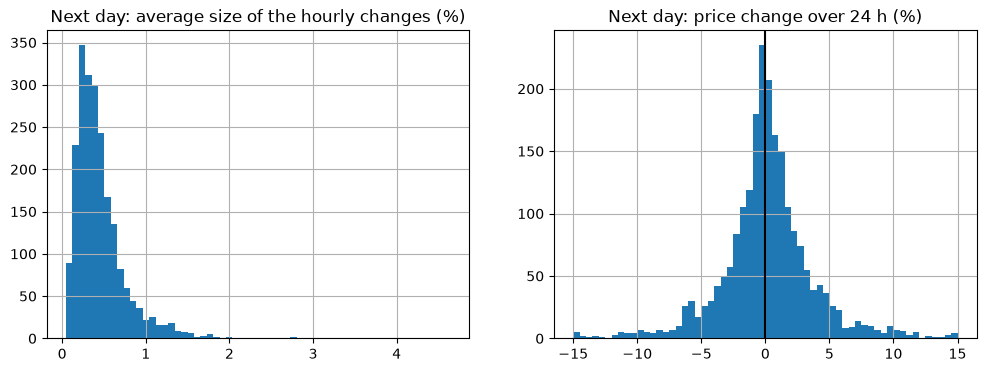

Share of up days in training: 0.509


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train["size_next"].hist(bins=60, ax=axes[0])
axes[0].set_title("Next day: average size of the hourly changes (%)")
train["ret_next"].clip(-15, 15).hist(bins=60, ax=axes[1])
axes[1].axvline(0, color="black")
axes[1].set_title("Next day: price change over 24 h (%)")
plt.show()

print("Share of up days in training:", round(train["up_next"].mean(), 3))

**Correlations** of the attributes with the two targets (training days):

In [7]:
corr = train[num_cols + ["size_next", "ret_next"]].corr()[["size_next", "ret_next"]].drop(["size_next", "ret_next"])
corr.round(3).sort_values("size_next", ascending=False)

,size_next,ret_next
size_1d,0.716,0.023
range_1d,0.693,0.035
vol_1d,0.676,0.023
vol_7d,0.663,0.020
volume_ratio,0.189,0.017
last_hour,-0.131,-0.063
ret_1d,-0.135,-0.075
ret_7d,-0.171,0.015


**What we see.**
- There are **3,190 days**: 2,184 for training (2018–2023) and 1,006 for testing (2024 – Oct 2026).
- The price went up on **50.9 %** of the training days, so up and down days are almost equally common (the classes are balanced).
- The move size is skewed: most days are calm (median 0.35 % per hour), a few are very wild (up to 4.6 %).
- **Move size:** today's volatility attributes are strongly correlated with tomorrow's move size: `size_1d` 0.72, `range_1d` 0.69, `vol_1d` 0.68. Wild days tend to be followed by wild days ("volatility clustering").
- **Direction:** no attribute is correlated with tomorrow's direction. All correlations with `ret_next` are between −0.08 and +0.04.

This already suggests the answer of the whole notebook: the **size** can be predicted, the **direction** hardly at all.

**Preprocessing pipeline** (as in Lab I, Part XII). A `ColumnTransformer` treats the two kinds of columns differently:
- numerical attributes: fill missing values with the median (`SimpleImputer`), then standardise (`StandardScaler`);
- the categorical `weekday`: one-hot encoding (`OneHotEncoder`), 7 columns of 0/1.

After `dropna()` there are no missing values, but the imputer keeps the pipeline safe for new data with gaps. The pipeline is fitted only on the training data. `make_pipe(model)` puts a fresh copy (`clone`) of it in front of every model, so each model learns its own scaling, and inside the cross-validation the scaler is fitted only on the training part of each fold.

In [8]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

def make_pipe(model):
    """A fresh copy of the preprocessing followed by the model, so models never share fitted steps."""
    return Pipeline([("prep", clone(preprocessing)), ("model", model)])

prepared = preprocessing.fit_transform(X_train)
print("Prepared training data:", prepared.shape)
print(preprocessing.get_feature_names_out())

Prepared training data: (2184, 15)
['num__ret_1d' 'num__ret_7d' 'num__size_1d' 'num__vol_1d' 'num__vol_7d'
 'num__range_1d' 'num__volume_ratio' 'num__last_hour'
 'cat__weekday_Friday' 'cat__weekday_Monday' 'cat__weekday_Saturday'
 'cat__weekday_Sunday' 'cat__weekday_Thursday' 'cat__weekday_Tuesday'
 'cat__weekday_Wednesday']


**Cross-validation for time series.** `cross_val_score` normally mixes the days at random. `TimeSeriesSplit` keeps the order: each fold trains on the past and validates on the following block of days.

In [9]:
cv = TimeSeriesSplit(n_splits=5)

for i, (tr, va) in enumerate(cv.split(X_train)):
    print(f"fold {i + 1}: train {X_train.index[tr[0]].date()} -> {X_train.index[tr[-1]].date()}"
          f" | validate {X_train.index[va[0]].date()} -> {X_train.index[va[-1]].date()}")

fold 1: train 2018-01-08 -> 2019-01-06 | validate 2019-01-07 -> 2020-01-05
fold 2: train 2018-01-08 -> 2020-01-05 | validate 2020-01-06 -> 2021-01-03
fold 3: train 2018-01-08 -> 2021-01-03 | validate 2021-01-04 -> 2022-01-02
fold 4: train 2018-01-08 -> 2022-01-02 | validate 2022-01-03 -> 2023-01-01
fold 5: train 2018-01-08 -> 2023-01-01 | validate 2023-01-02 -> 2023-12-31


## 2. How big will the moves be? Regression (Lab II)

Target: `size_next`, the average size of the next day's hourly changes. Two simple baselines show whether a model is useful at all:
- **mean:** always predict the average of the training days (`DummyRegressor`);
- **same as today:** predict that tomorrow's moves will be as big as today's (`size_1d`).

In [10]:
y_train_size, y_test_size = train["size_next"], test["size_next"]

def rmse_cv(model):
    scores = -cross_val_score(make_pipe(model),
                              X_train, y_train_size, cv=cv, scoring="neg_root_mean_squared_error")
    return scores.mean(), scores.std()

regressors = {
    "Mean (baseline)": DummyRegressor(),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

rows = []
for name, model in regressors.items():
    pipe = make_pipe(model).fit(X_train, y_train_size)
    train_rmse = np.sqrt(mean_squared_error(y_train_size, pipe.predict(X_train)))
    cv_mean, cv_std = rmse_cv(model)
    rows.append([name, train_rmse, cv_mean, cv_std])

same_as_today = np.sqrt(np.mean([mean_squared_error(y_train_size.iloc[va], X_train["size_1d"].iloc[va])
                                 for _, va in cv.split(X_train)]))
rows.append(["Same as today (baseline)", np.nan, same_as_today, np.nan])

pd.DataFrame(rows, columns=["model", "train RMSE", "CV RMSE", "CV std"]).set_index("model").round(4)

,train RMSE,CV RMSE,CV std
model,,,
Mean (baseline),0.3262,0.3104,0.0407
Linear Regression,0.2035,0.1994,0.0509
Decision Tree,0.0000,0.2624,0.0476
Random Forest,0.0762,0.1972,0.0449
Same as today (baseline),NaN,0.2397,NaN


**What we see** (cross-validated RMSE on 2019–2023, lower is better):
- **Linear Regression (0.199)** and **Random Forest (0.197)** are much better than predicting the mean (0.310), and also better than "same as today" (0.240). They combine several attributes, e.g. today's moves *and* the weekly volatility, which smooths out one unusual day.
- **The Decision Tree overfits** exactly as in Lab II: training RMSE 0.000 (it memorised every day), but CV RMSE 0.262, worse than the linear model. The Random Forest averages 200 different trees and overfits much less (train 0.076, CV 0.197).
- The CV standard deviation (≈ 0.04–0.05) is about as large as some of the differences between the models, because the years differ a lot: the average move size was 0.62 % in 2021 but only 0.27 % in 2023.

**Fine-tuning** (Lab II, Part VIII). The fully grown trees overfit, so we search over how deep the trees of the Random Forest may grow and how many days each leaf must contain:

In [11]:
rf_pipe = make_pipe(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))

param_grid = {
    "model__max_depth": [3, 6, 10, None],
    "model__min_samples_leaf": [1, 10, 30],
}

grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring="neg_root_mean_squared_error")
grid.fit(X_train, y_train_size)

print("Best parameters:", grid.best_params_)
print("Best CV RMSE:", round(-grid.best_score_, 4))

pd.DataFrame(grid.cv_results_)[["param_model__max_depth", "param_model__min_samples_leaf", "mean_test_score"]] \
  .assign(CV_RMSE=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").sort_values("CV_RMSE").round(4).head(6)

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1}
Best CV RMSE: 0.1972


,param_model__max_depth,param_model__min_samples_leaf,CV_RMSE
9,None,1,0.1972
6,10,1,0.1976
3,6,1,0.1979
10,None,10,0.1999
7,10,10,0.2000
4,6,10,0.2007


**Feature importance** of the best Random Forest (Lab II, Part IX):

In [12]:
best_rf = grid.best_estimator_
importances = pd.Series(best_rf["model"].feature_importances_,
                        index=best_rf["prep"].get_feature_names_out()).sort_values(ascending=False)
importances.round(3).head(10)

num__size_1d             0.513
num__ret_1d              0.100
num__ret_7d              0.089
num__vol_7d              0.080
num__range_1d            0.058
num__last_hour           0.043
num__vol_1d              0.043
num__volume_ratio        0.035
cat__weekday_Saturday    0.013
cat__weekday_Monday      0.007
dtype: float64

**Final evaluation on the test set** (2024 onwards, used only once). Besides RMSE we show MAE and R², the share of the day-to-day variation that the model explains (0 = no better than the mean, 1 = perfect):

In [13]:
def regression_report(name, pred):
    return [name, np.sqrt(mean_squared_error(y_test_size, pred)), mean_absolute_error(y_test_size, pred),
            r2_score(y_test_size, pred)]

lin = make_pipe(LinearRegression()).fit(X_train, y_train_size)

test_rows = [
    regression_report("Mean (baseline)", np.full(len(test), y_train_size.mean())),
    regression_report("Same as today (baseline)", X_test["size_1d"]),
    regression_report("Linear Regression", lin.predict(X_test)),
    regression_report("Random Forest (tuned)", best_rf.predict(X_test)),
]
pd.DataFrame(test_rows, columns=["model", "RMSE", "MAE", "R2"]).set_index("model").round(4)

,RMSE,MAE,R2
model,,,
Mean (baseline),0.2101,0.1781,-0.5808
Same as today (baseline),0.1669,0.1230,0.0023
Linear Regression,0.1209,0.0874,0.4766
Random Forest (tuned),0.1282,0.0920,0.4118


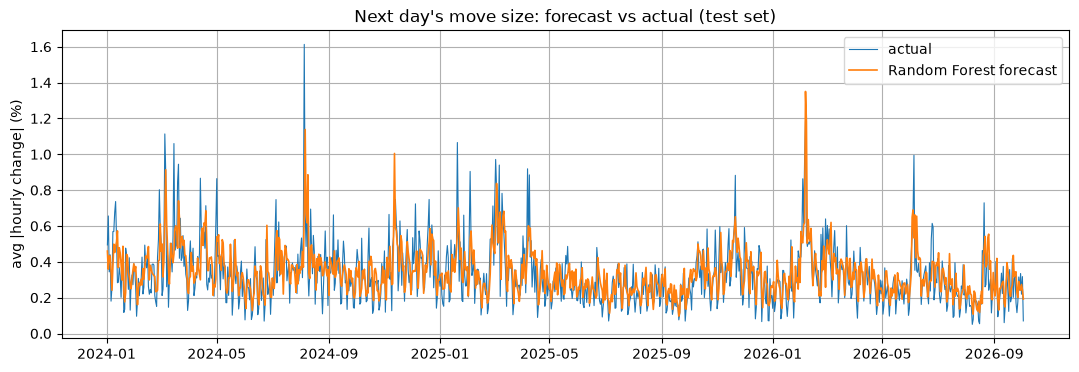

In [14]:
plt.figure(figsize=(13, 4))
plt.plot(test.index, y_test_size, lw=0.8, label="actual")
plt.plot(test.index, best_rf.predict(X_test), lw=1.2, label="Random Forest forecast")
plt.ylabel("avg |hourly change| (%)")
plt.title("Next day's move size: forecast vs actual (test set)")
plt.legend()
plt.grid(True)
plt.show()

**What we see.**
- **Grid search:** the best Random Forest uses fully grown trees (`max_depth=None`, `min_samples_leaf=1`), but the top six settings are within 0.003 of each other, so the choice hardly matters.
- **Feature importance:** today's average move size (`size_1d`) dominates (0.51). The weekday is almost irrelevant. This matches the correlations.
- **Test set (2024 onwards):**
  - **Linear Regression is the best model: R² = 0.48**, RMSE 0.121, MAE 0.087. It explains about half of the day-to-day variation in how big tomorrow's moves are.
  - The tuned Random Forest is a bit worse (R² 0.41). On this data the simple model generalises better.
  - **Mean (baseline)** has a negative R² (−0.58). The test years were calmer than 2018–2023, so the average of the training days is too high. The models adapt because they use the *current* volatility.
  - **"Same as today"** has R² ≈ 0: it gets the level right but overreacts to every single wild day.
- **The plot:** the forecast follows the calm and wild periods of 2024–2026 and rises after the large spikes. It cannot predict a spike on a calm day before it happens (e.g. August 2024), because nothing in the past days announces it.

**Conclusion:** the move size is predictable to a useful degree, mainly because volatility persists from one day to the next.

## 3. Which way will the price go? Classification (Lab III)

Target: `up_next`, 1 if the price is higher after 24 hours. The classifiers from Lab III plus a Random Forest, compared with **always predicting the more common class** (`DummyClassifier`). Accuracy is measured with the same time-series cross-validation:

In [15]:
y_train_up, y_test_up = train["up_next"], test["up_next"]

classifiers = {
    "Majority class (baseline)": DummyClassifier(strategy="most_frequent"),
    "SGD Classifier": SGDClassifier(random_state=42),
    "KNN (k = 50)": KNeighborsClassifier(n_neighbors=50),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=30, random_state=42, n_jobs=-1),
}

rows = []
fitted = {}
for name, model in classifiers.items():
    pipe = make_pipe(model)
    cv_acc = cross_val_score(pipe, X_train, y_train_up, cv=cv, scoring="accuracy")
    fitted[name] = pipe.fit(X_train, y_train_up)
    rows.append([name, cv_acc.mean(), cv_acc.std(), accuracy_score(y_test_up, fitted[name].predict(X_test))])

pd.DataFrame(rows, columns=["model", "CV accuracy", "CV std", "test accuracy"]).set_index("model").round(3)

,CV accuracy,CV std,test accuracy
model,,,
Majority class (baseline),0.504,0.039,0.506
SGD Classifier,0.520,0.034,0.499
KNN (k = 50),0.512,0.008,0.490
Random Forest,0.535,0.017,0.513


**Confusion matrix, precision, recall and F1** of the Random Forest on the test set (Lab III, Parts V–VI). Rows are the actual days, columns the predictions:

In [16]:
rf_clf = fitted["Random Forest"]
pred_up = rf_clf.predict(X_test)

print(pd.DataFrame(confusion_matrix(y_test_up, pred_up),
                   index=["actual down", "actual up"], columns=["predicted down", "predicted up"]))
print()
print("Share of up days in the test set:", round(y_test_up.mean(), 3))
print("Precision (up):", round(precision_score(y_test_up, pred_up), 3))
print("Recall (up):   ", round(recall_score(y_test_up, pred_up), 3))
print("F1 (up):       ", round(f1_score(y_test_up, pred_up), 3))

             predicted down  predicted up
actual down             251           246
actual up               244           265

Share of up days in the test set: 0.506
Precision (up): 0.519
Recall (up):    0.521
F1 (up):        0.52


**ROC curve and AUC** (Lab III, Part IX). The AUC does not depend on one threshold: 0.5 = random guessing, 1.0 = perfect ranking of up and down days:

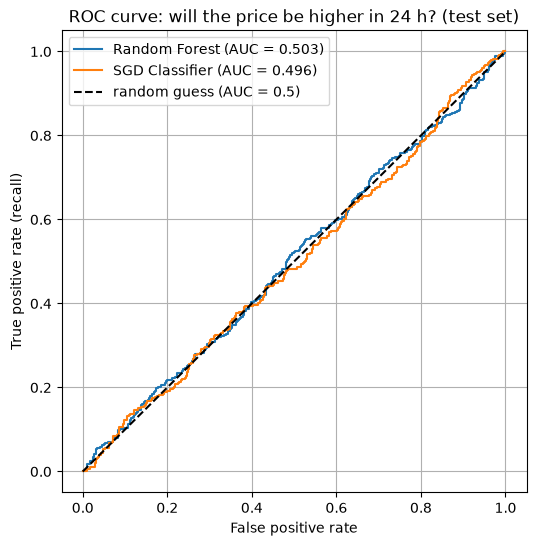

In [17]:
proba_up = rf_clf.predict_proba(X_test)[:, 1]
score_sgd = fitted["SGD Classifier"].decision_function(X_test)

plt.figure(figsize=(6, 6))
for name, score in [("Random Forest", proba_up), ("SGD Classifier", score_sgd)]:
    fpr, tpr, _ = roc_curve(y_test_up, score)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test_up, score):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random guess (AUC = 0.5)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve: will the price be higher in 24 h? (test set)")
plt.legend()
plt.grid(True)
plt.show()

**Changing the threshold** (Lab III, Part VII). If the model is only allowed to say "up" when it is quite sure, does it become right more often?

In [18]:
for threshold in [0.5, 0.55, 0.6]:
    chosen = proba_up >= threshold
    if chosen.sum() > 0:
        print(f"threshold {threshold:.2f}: says 'up' on {chosen.sum():4d} days, right on {y_test_up[chosen].mean():.1%} of them")

threshold 0.50: says 'up' on  511 days, right on 51.9% of them
threshold 0.55: says 'up' on  217 days, right on 51.6% of them
threshold 0.60: says 'up' on   50 days, right on 60.0% of them


**What we see.**
- **Accuracy:** no classifier beats the coin flip on the test set. The majority class gets 50.6 %, and the models 49.0–51.3 %.
- **Cross-validation:** the Random Forest's 53.5 % CV accuracy did not hold up on new data (51.3 % on the test set).
- **Confusion matrix:** the Random Forest makes almost as many mistakes as hits in both classes (251 and 265 right, 246 and 244 wrong). Precision, recall and F1 are all ≈ 0.52.
- **ROC-AUC:** 0.503 (Random Forest) and 0.496 (SGD). Both curves lie on the diagonal of random guessing, so the models cannot even *rank* up days above down days.
- **Threshold:** a higher threshold makes the model more selective. At 0.60 it says "up" on only 50 days and is right on 30 of them (60 %). With only 50 days this can easily be luck: the chance of ≥ 30 hits out of 50 by pure guessing is about 12 %. Precision does not rise steadily with the threshold either (51.9 % → 51.6 % → 60 %), which a real signal would show.

**Conclusion:** with daily data and these attributes, the direction of the next day is **not predictable**. This agrees with version 3 of the project and with the idea of an efficient market: if the direction were easy to predict, traders would already have used it.

## 4. Support Vector Machines (Lab IV)

The same two questions with SVMs: `SVR` for the move size and `SVC` for the direction, both with the RBF kernel and the same preprocessing. SVMs need scaled inputs, which the pipeline already provides. For the SVR we try a few values of `C` (how strongly errors are penalised) with the time-series cross-validation:

In [19]:
svr_grid = GridSearchCV(
    make_pipe(SVR(kernel="rbf", epsilon=0.05)),
    {"model__C": [0.1, 1, 10]},
    cv=cv, scoring="neg_root_mean_squared_error",
)
svr_grid.fit(X_train, y_train_size)
svr_pred = svr_grid.predict(X_test)

print("Best C:", svr_grid.best_params_["model__C"], "| CV RMSE:", round(-svr_grid.best_score_, 4))
print("SVR test RMSE:", round(np.sqrt(mean_squared_error(y_test_size, svr_pred)), 4),
      "| R2:", round(r2_score(y_test_size, svr_pred), 4))

svc = make_pipe(SVC(kernel="rbf", C=1)).fit(X_train, y_train_up)
svc_pred = svc.predict(X_test)
print("SVC test accuracy:", round(accuracy_score(y_test_up, svc_pred), 3),
      "| predicts 'up' on", round(svc_pred.mean(), 3), "of the days",
      "| AUC:", round(roc_auc_score(y_test_up, svc.decision_function(X_test)), 3))

Best C: 1 | CV RMSE: 0.2049
SVR test RMSE: 0.1223 | R2: 0.4646


SVC test accuracy: 0.512 | predicts 'up' on 0.559 of the days | AUC: 0.511


**What we see.**
- **SVR (move size):**
  - It reaches a test R² of **0.46** (RMSE 0.122), almost the same as Linear Regression (0.48) and better than the Random Forest.
  - The RBF kernel could bend the relationship, but there is little to bend: the move size depends on today's volatility almost linearly.
  - `C = 1` was best. `C = 0.1` regularises too much, and `C = 10` fits the wild training days too closely.
- **SVC (direction):**
  - 51.2 % accuracy and an AUC of 0.511, again a coin flip.
  - It says "up" on 56 % of the days, i.e. it mostly learned that up days are slightly more common.

As in Lab IV, the SVMs need scaled inputs (done by the pipeline). They do not change the conclusion: size yes, direction no.

## 5. What kind of day was it? Clustering (Lab V)

K-Means groups days by how the market behaved, **without** looking at the next day. We use three attributes: the day's price change, its volatility and its volume compared with the week. They are standardised first, because K-Means uses distances.

**How many clusters?** The elbow method (Lab V, Part VIII):

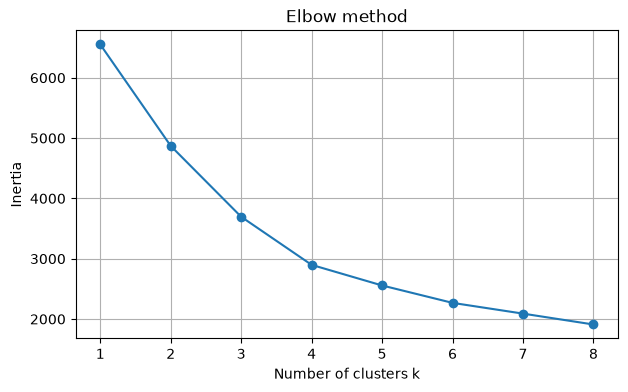

In [20]:
cluster_cols = ["ret_1d", "vol_1d", "volume_ratio"]
cluster_scaler = StandardScaler().fit(train[cluster_cols])
Z_train = cluster_scaler.transform(train[cluster_cols])

inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z_train).inertia_ for k in range(1, 9)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), inertias, "o-")
plt.xlabel("Number of clusters k")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.grid(True)
plt.show()

We take **k = 4** (where the curve bends) and describe each cluster by its centre in the original units:

In [21]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z_train)

centres = pd.DataFrame(cluster_scaler.inverse_transform(kmeans.cluster_centers_), columns=cluster_cols)
centres["days (train)"] = np.bincount(kmeans.labels_)
centres.round(3)

,ret_1d,vol_1d,volume_ratio,days (train)
0,-6.020,1.377,0.363,213
1,0.214,0.406,-0.714,589
2,5.780,1.058,0.259,293
3,-0.269,0.507,0.028,1089


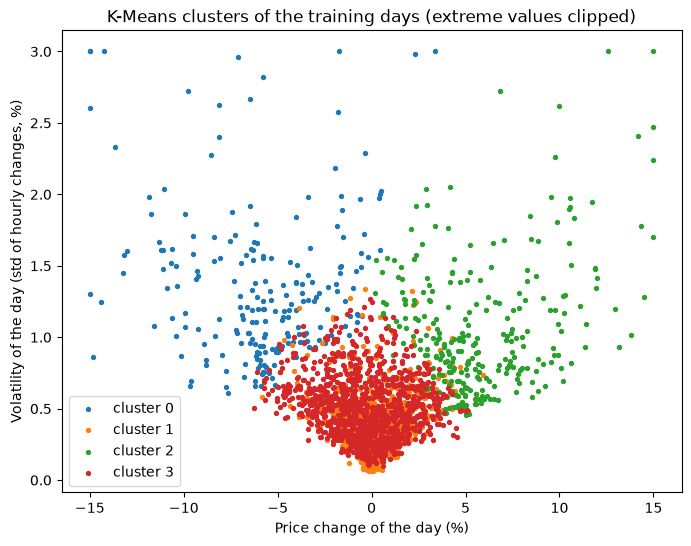

In [22]:
plt.figure(figsize=(8, 6))
for k in range(4):
    part = train[kmeans.labels_ == k]
    plt.scatter(part["ret_1d"].clip(-15, 15), part["vol_1d"].clip(upper=3), s=8, label=f"cluster {k}")
plt.xlabel("Price change of the day (%)")
plt.ylabel("Volatility of the day (std of hourly changes, %)")
plt.title("K-Means clusters of the training days (extreme values clipped)")
plt.legend()
plt.show()

**Do the clusters say anything about the next day?** We assign the **test** days to the clusters learned on the training days and compare what happened the day after:

In [23]:
test_clusters = kmeans.predict(cluster_scaler.transform(test[cluster_cols]))

test.assign(cluster=test_clusters).groupby("cluster").agg(
    days=("up_next", "size"),
    next_day_move_size=("size_next", "mean"),
    next_day_up_share=("up_next", "mean"),
).round(3)

,days,next_day_move_size,next_day_up_share
cluster,,,
0,36,0.541,0.528
1,298,0.294,0.540
2,73,0.408,0.493
3,599,0.322,0.489


**What we see.**
- **Elbow:** the inertia falls quickly up to k = 4 and slowly after that, so 4 clusters is a reasonable choice.
- **The 4 clusters** are easy to name from their centres:
  - **cluster 0, crash days:** −6.0 %, high volatility, high volume (213 training days);
  - **cluster 1, quiet days:** +0.2 %, low volatility, volume well below the weekly average (589);
  - **cluster 2, rally days:** +5.8 %, high volatility, high volume (293);
  - **cluster 3, normal days:** −0.3 %, average volatility and volume (1,089, the largest group).
- **The scatter plot:** the clusters are separated mainly by the day's price change (left = crash, right = rally) and by volatility (bottom = quiet).

**The next day (test set):**
- **Move size depends on the cluster:** after crash days the next day's moves are almost **twice as big** (0.54 %) as after quiet days (0.29 %). The clustering found real market regimes, and the regime carries over to the next day, the same effect the regression models use.
- **Direction does not:** the share of up days is 49–54 % in every cluster. Even "crash" days are not followed by more down days (or more rebounds) than other days. The crash cluster has only 36 test days, so its 52.8 % is very uncertain.

Clustering is unsupervised: K-Means never saw the targets, yet it found groups that differ in tomorrow's move size, but not in tomorrow's direction.

## 6. Neural network (Lab VI)

Finally a small Keras MLP for the move size: two hidden ReLU layers and one linear output neuron, trained with MSE. The last 20 % of the training days (in time order) are the validation set, and **early stopping** (Lab VI, Part XI) stops training when the validation loss stops improving.

In [24]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from tensorflow import keras

keras.utils.set_random_seed(42)

n_valid = int(len(train) * 0.2)
nn_prep = clone(preprocessing)
X_tr_nn = nn_prep.fit_transform(X_train.iloc[:-n_valid])
X_va_nn = nn_prep.transform(X_train.iloc[-n_valid:])
X_te_nn = nn_prep.transform(X_test)
y_tr_nn, y_va_nn = y_train_size.iloc[:-n_valid], y_train_size.iloc[-n_valid:]

mlp = keras.models.Sequential([
    keras.layers.Input(shape=X_tr_nn.shape[1:]),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1),
])
mlp.compile(loss="mse", optimizer=keras.optimizers.SGD(learning_rate=0.01))

early_stopping = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)
history = mlp.fit(X_tr_nn, y_tr_nn, epochs=500, validation_data=(X_va_nn, y_va_nn),
                  callbacks=[early_stopping], verbose=0)

mlp_pred = mlp.predict(X_te_nn, verbose=0).ravel()
print("Epochs run:", len(history.history["loss"]), "| best epoch:", int(np.argmin(history.history["val_loss"])) + 1)
print("MLP test RMSE:", round(np.sqrt(mean_squared_error(y_test_size, mlp_pred)), 4),
      "| R2:", round(r2_score(y_test_size, mlp_pred), 4))

Epochs run: 148 | best epoch: 128
MLP test RMSE: 0.1326 | R2: 0.37


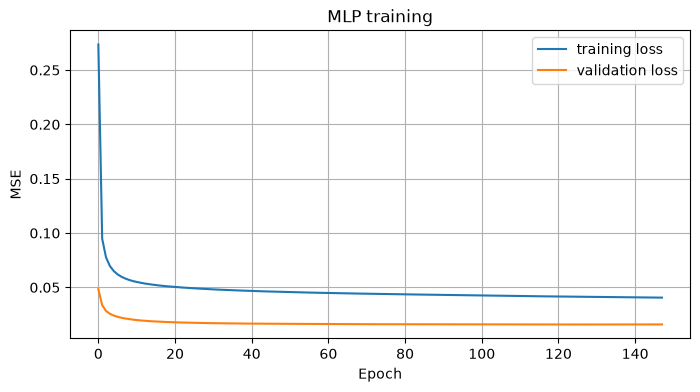

In [25]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MLP training")
plt.legend()
plt.grid(True)
plt.show()

**What we see.**
- **Training:**
  - Early stopping ended after 148 epochs and restored the weights from epoch 128, where the validation loss was lowest.
  - The validation loss is lower than the training loss the whole time. This is not a mistake: the validation days (Oct 2022 – Dec 2023) were much calmer than the earlier training days (average move size 0.27 % vs 0.50 %), so their errors are smaller.
- **Test set:** RMSE 0.133, **R² = 0.37**. That is clearly useful (much better than the baselines), but **worse than the simple Linear Regression** (0.48).
- **Why:** with about 1,750 training days and a relationship that is nearly linear, the network has nothing extra to learn and more parameters that can fit noise. Neural networks pay off with large amounts of data and complex patterns (images in Lab VI), not with a small table of 15 columns.

## 7. Summary

All models on the test set (2024 onwards):

In [26]:
size_results = pd.DataFrame(test_rows + [regression_report("SVR", svr_pred), regression_report("MLP (Keras)", mlp_pred)],
                            columns=["model", "RMSE", "MAE", "R2"]).set_index("model")

direction_results = pd.DataFrame({
    "test accuracy": [accuracy_score(y_test_up, fitted[n].predict(X_test)) for n in classifiers] + [accuracy_score(y_test_up, svc_pred)],
}, index=list(classifiers) + ["SVC"])

print("How big will the moves be? (regression)")
display(size_results.round(4))
print("Which way will the price go? (classification)")
display(direction_results.round(3))

How big will the moves be? (regression)


,RMSE,MAE,R2
model,,,
Mean (baseline),0.2101,0.1781,-0.5808
Same as today (baseline),0.1669,0.1230,0.0023
Linear Regression,0.1209,0.0874,0.4766
Random Forest (tuned),0.1282,0.0920,0.4118
SVR,0.1223,0.0872,0.4646
MLP (Keras),0.1326,0.0984,0.3700


Which way will the price go? (classification)


,test accuracy
Majority class (baseline),0.506
SGD Classifier,0.499
KNN (k = 50),0.490
Random Forest,0.513
SVC,0.512


**Conclusions:**

1. **How big will tomorrow's moves be?**
   - **Predictable.** The best model, plain **Linear Regression**, explains about half of the variation (test R² 0.48). SVR (0.46), Random Forest (0.41) and the Keras MLP (0.37) follow.
   - The key information is today's volatility: calm days follow calm days, and wild days follow wild days.
   - More complex models did not help, because the relationship is close to linear and there are only about 2,000 training days.

2. **Which way will the price go?**
   - **Not predictable** with these methods. Every classifier stays at 49–51 % accuracy and an AUC of ≈ 0.50, the same as a coin flip.
   - Precision, recall, the ROC curve and the threshold experiment all confirm it.

3. **What kind of day was it?**
   - K-Means finds four clear regimes (crash, rally, quiet and normal days).
   - The regime tells us how big the next day's moves will be, but not their direction.

**Answer to the project question:** the task "by how many % will each hour change" should be split into two parts. The **size** of the changes, and therefore the range in which the price will probably move, can be forecast. The **direction** practically cannot. This notebook reaches the same conclusion as version 3 of the project, using only the basic methods from the course labs (pipeline, regression, cross-validation, grid search, classification metrics, SVM, K-Means, MLP).

Lab techniques used: `Pipeline` / `ColumnTransformer` / `SimpleImputer` / `StandardScaler` / `OneHotEncoder` (Lab I); `LinearRegression`, `DecisionTreeRegressor`, `RandomForestRegressor`, `cross_val_score`, `GridSearchCV`, feature importance (Lab II); `SGDClassifier`, `KNeighborsClassifier`, confusion matrix, precision / recall / F1, ROC / AUC, threshold (Lab III); `SVR`, `SVC` (Lab IV); `KMeans`, elbow method (Lab V); Keras `Sequential`, early stopping (Lab VI). The only additions are `TimeSeriesSplit`, which replaces the random split because the data is a time series, and `clone`, which gives every model its own copy of the preprocessing.